In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score,ConfusionMatrixDisplay, PrecisionRecallDisplay

## 1. Data exploration


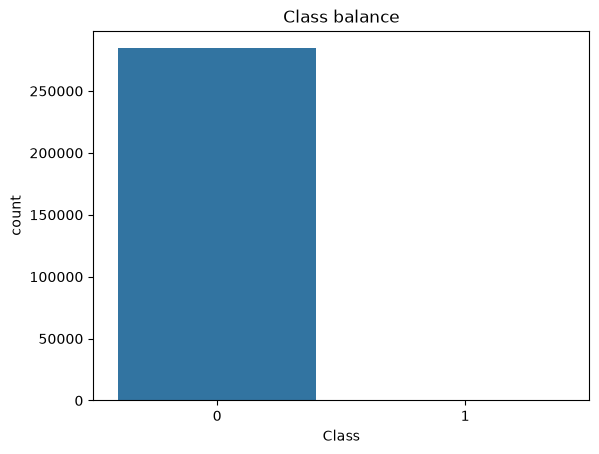

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [76]:
df = pd.read_csv('data/creditcard.csv')

sns.countplot(x="Class", data=df)
plt.title("Class balance")
plt.show()

df.head()


In [77]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [78]:
print("Shape:", df.shape)
print("Missing Values:", df.isna().sum().sum())
print("Dupe Values:", df.duplicated().sum())
print("Fraud rate: {:.3%}".format(df["Class"].mean()))
print(df[["Time", "Amount"]].describe())

Shape: (284807, 31)
Missing Values: 0
Dupe Values: 1081
Fraud rate: 0.173%
                Time         Amount
count  284807.000000  284807.000000
mean    94813.859575      88.349619
std     47488.145955     250.120109
min         0.000000       0.000000
25%     54201.500000       5.600000
50%     84692.000000      22.000000
75%    139320.500000      77.165000
max    172792.000000   25691.160000


**Observations:**
In this data there are 284807 raws transactions with 31 columns, there where no missing values with only 0.173% of transactions being fraud (492).
This shows that the classes are extremely imbalanaced, this will mean the accuracy will be misleading because a model that predicts something as "not fraud" would score high.
Only: Time, Amount and Class can be interpreted directly opposed to V1-V28


In [79]:
df.head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


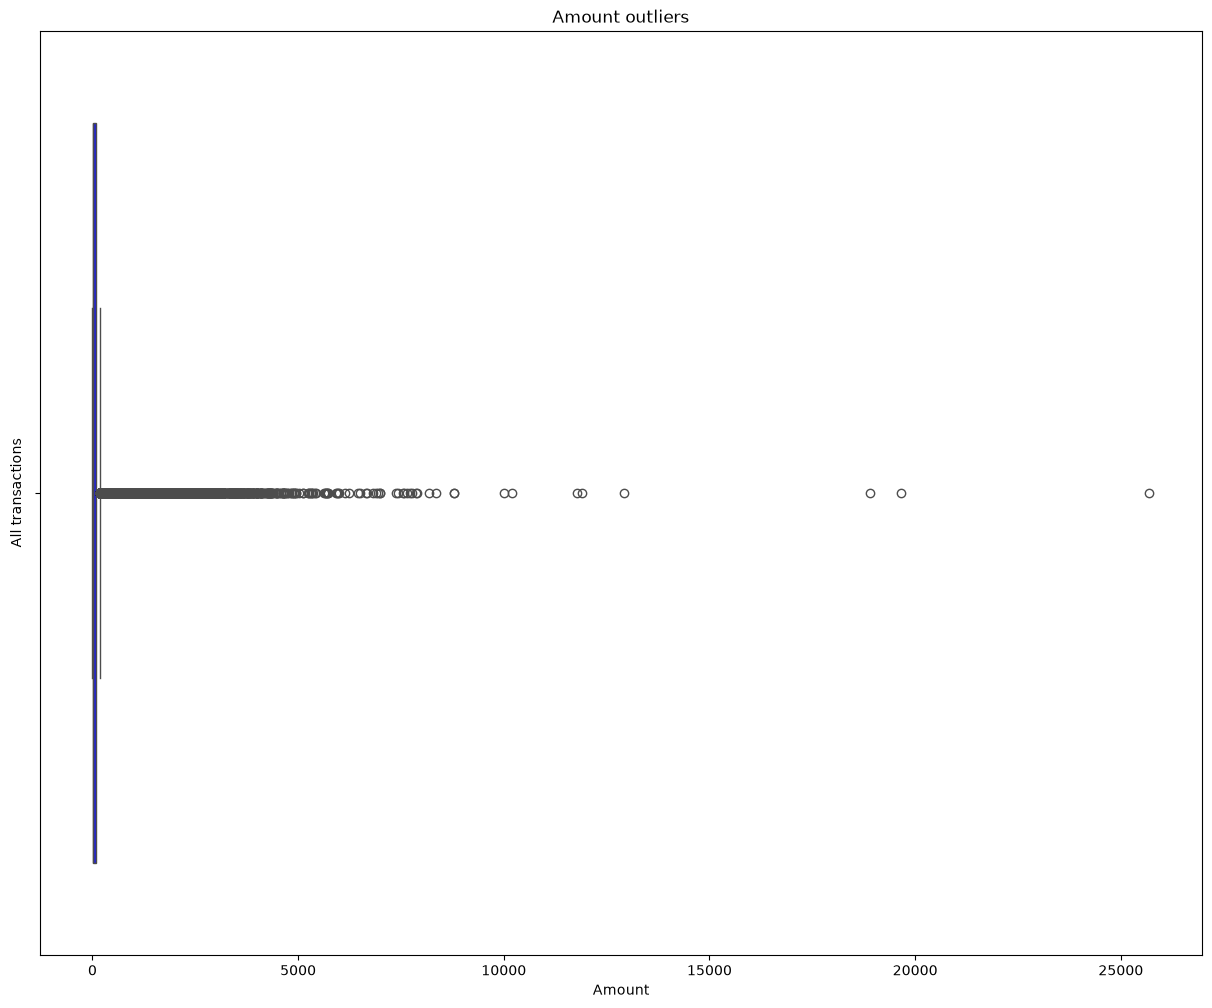

In [80]:
plt.figure(figsize =(15,12))
sns.boxplot(x = 'Amount', data = df, color = "blue")
plt.ylabel("All transactions")
plt.title("Amount outliers")
plt.show()

([<matplotlib.axis.YTick at 0x1b7871b1d10>,
 [Text(0, 0, 'Legitimate'), Text(0, 1, 'Fraud')])

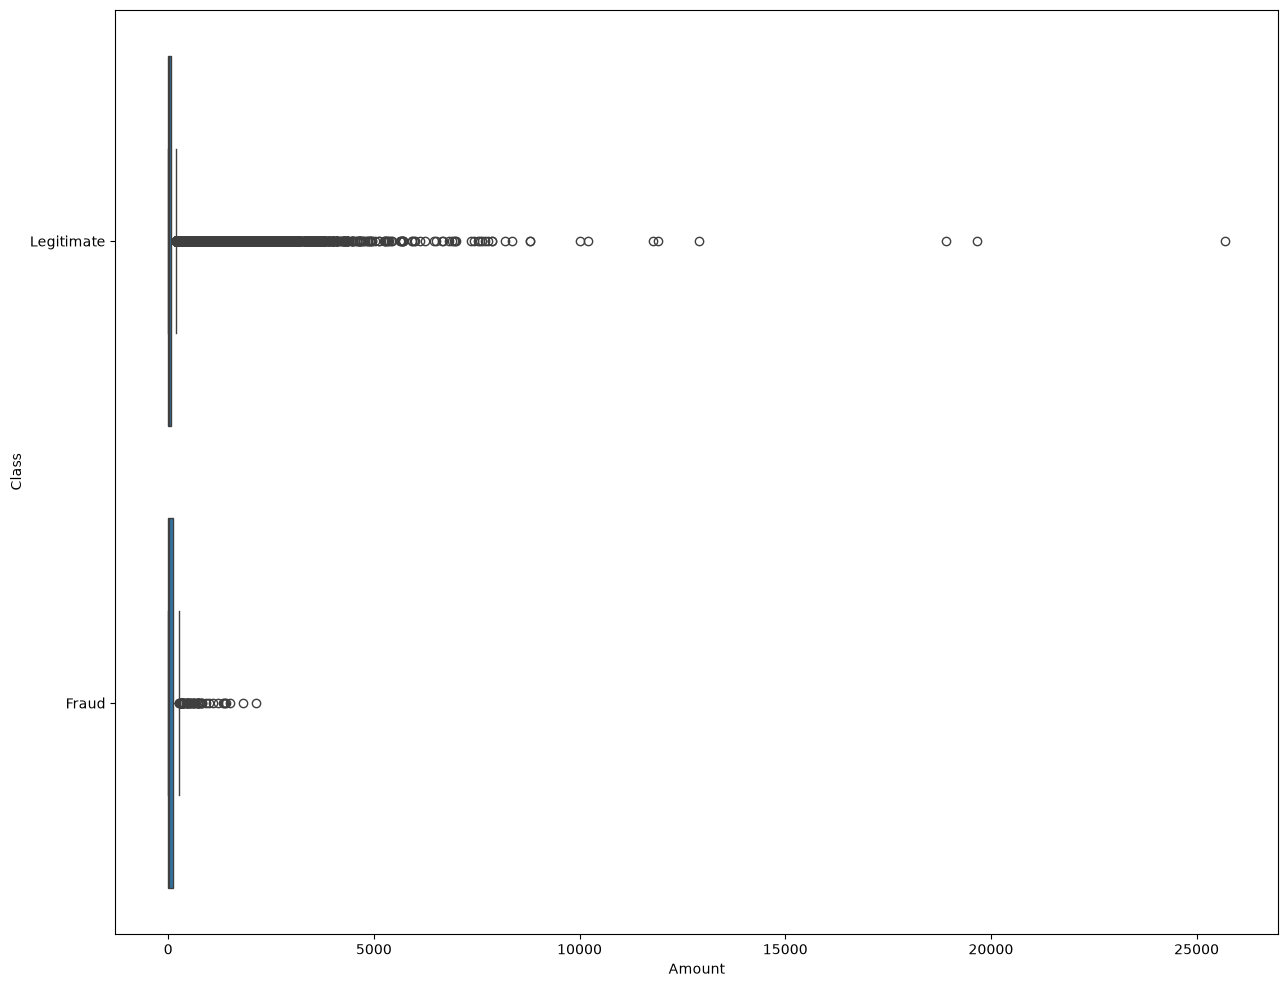

In [81]:
plt.figure(figsize =(15,12))
sns.boxplot(x = 'Amount', y = 'Class', data = df, orient = "h")
plt.yticks([0,1], ["Legitimate", "Fraud"])

**Observations:**
Amount appears to be heavily right skewed, from the describe function from the previous cell, we can distinguish that the median is 22.0 but the maximum is 25691. 

Due to this the box is heavily squashed and thousands of these points are flagged to be outliers even they are genuine transactions and not errors. 

This is why i kept them knowing theyre real transactions. 

These values depending on the context should be considered as they are. 

Fraud amounts are generally small and do not go above about 2,100, so Amount alone cannot separate the classes.

## 2. Data cleaning

In [82]:
n_dupes = df.duplicated().sum()
n_fraud_dupes = df[df.duplicated()]["Class"].sum()
print("Duplicates:", n_dupes, "of which fraud:", n_fraud_dupes)


df = df.drop_duplicates().reset_index(drop=True)
print("Rows after cleaning:", len(df), "| frauds:", df["Class"].sum())

Duplicates: 1081 of which fraud: 19
Rows after cleaning: 283726 | frauds: 473


**Decision:**
During data cleaning i removed 1081 rows in which 19 of those where frauds leaving me with 283726 rows, 473 being fraud. In the context of transactions, identical rows are the same transaction that has been recorded twice. 

If these copies remained in the data during training and testing, the copies would leak into both stages and inflate the results. Since there were not missing values, imputationw was not needed.

## 3. Feature engineering


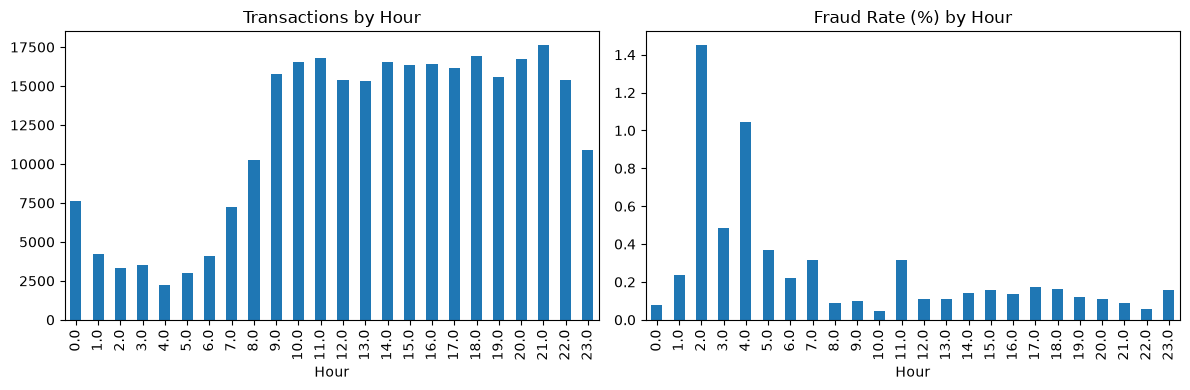

Amount skew: 16.978803370060486
          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87
Amount skew: 0.16141018223366596
Extra duplicates removed: 2804 | frauds kept: 473


In [ ]:
df["Hour"] = (df['Time'] // 3600) % 24

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
df["Hour"].value_counts().sort_index().plot.bar()
plt.title("Transactions by Hour")

plt.subplot(1, 2, 2)
(df.groupby("Hour")["Class"].mean() * 100).plot.bar()
plt.title("Fraud Rate (%) by Hour")

plt.tight_layout()
plt.show()

print("Amount skew:", df["Amount"].skew())
#amount is skewed so we can use log to fix this(ai reccommendation)
df["Amount_log"] = np.log1p(df["Amount"])

fraud = df.groupby("Class")["Amount"].describe().round(2)
print(fraud)

df = df.drop(columns = ['Time', 'Amount'])

print("Amount skew:", df["Amount_log"].skew())

#IMPORTANT DUPLICATE REMOVER SO THAT THE TEST TRAINMING SPLIT DDOESNT SHARE ROWS
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Extra duplicates removed:", before - len(df), "| frauds kept:", df["Class"].sum())

**Decisions:**

'Time' in this data set is in seconds, so it keeps increasing, this would not be good for generalisation for the model as reducing the precision by converting it to hours acts as a fitler that reduces high frequency noise and prevents the model from overfitting, converting it to hours also captures a stronger and easier pattern for systems and human perception. The fraud rate by hour plot shows that fraud varies throughout the day so we can see this feature does carry some signal(meaningful patterns).

'Amount' had a skew of 17, so i got ai reccomendation of how to lower it, i applied log1p to reduce it, log lowers the value while keeping its significance. which brought it down to 16, still not good but better than before. `log1p` is used because some amounts are 0.

After dropping `Time`, some rows became identical (same features, different timestamp). I removed 2,804 of these (no frauds lost), because otherwise copies could appear in both train and test.


## 4. Data partitioning

In [84]:
X = df.drop(columns = 'Class')
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, stratify=y, random_state= 42)
#reminders:
#X_train + y_train	Used to teach the model
#X_test + y_test	Used to check the model on unseen data

print("Train:", X_train.shape, "| fraud rate: {:.3%}".format(y_train.mean()))
print("Test: ", X_test.shape, "| fraud rate: {:.3%}".format(y_test.mean()))


overlap = pd.merge(X_train.drop_duplicates(), X_test.drop_duplicates(), how="inner")
print("Rows shared between train and test:", len(overlap))

Train: (196645, 30) | fraud rate: 0.168%
Test:  (84277, 30) | fraud rate: 0.168%
Rows shared between train and test: 0


**Decision:**

For test and training i used a 70/30 split, stratified was used on class as to keep the original fraud at 0.168%

The train set has 196,645 rows and the test set 84,277 (about 142 frauds).

The split is done before scaling so no information from the test set influences preprocessing. The overlap check shows 0 rows shared between train and test.

## 5. Feature scaling

In [85]:
scale_column = ['Amount_log', 'Hour']
scaler = StandardScaler()

X_train[scale_column] =  scaler.fit_transform(X_train[scale_column])
X_test[scale_column] =  scaler.transform(X_test[scale_column])

X_train[scale_column].describe().loc[["mean", "std"]] #ai recc



,Amount_log,Hour
mean,1.837016e-16,3.324261e-17
std,1.000003e+00,1.000003e+00


Mean = 0; average is now 0 for each column, its now meassured in above or below avg. Positive means above avg and negative means below avg
Std = 1: a typical row sits about 1 unit from the average. A value of +2 is unusually high, and -2 is unusually low.

I standardised `Amount_log` and `Hour` (mean 0, standard deviation 1) using a scaler fitted on the training data only and then applied to the test data, to avoid data leakage.

Logistic regression needs scaled features; the random forest does not 

`Amount_log` and `Hour` were on very different scales (about 0–10 and 0–23). I standardised them so both have a mean of 0 and a standard deviation of 1. This stops the larger numbers from dominating the logistic regression model and helps it train properly. I fitted the scaler on the training data only and applied it to the test data, to avoid data leakage(if you fit the scaler on all the data, the mean and standard deviation include the test rows).



Logistic regression
              precision    recall  f1-score   support

           0      1.000     0.976     0.988     84135
           1      0.059     0.894     0.110       142

    accuracy                          0.976     84277
   macro avg      0.529     0.935     0.549     84277
weighted avg      0.998     0.976     0.986     84277

Confusion matrix:
 [[82095  2040]
 [   15   127]]
PR-AUC: 0.753

Random forest
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     84135
           1      0.818     0.824     0.821       142

    accuracy                          0.999     84277
   macro avg      0.909     0.912     0.910     84277
weighted avg      0.999     0.999     0.999     84277

Confusion matrix:
 [[84109    26]
 [   25   117]]
PR-AUC: 0.84


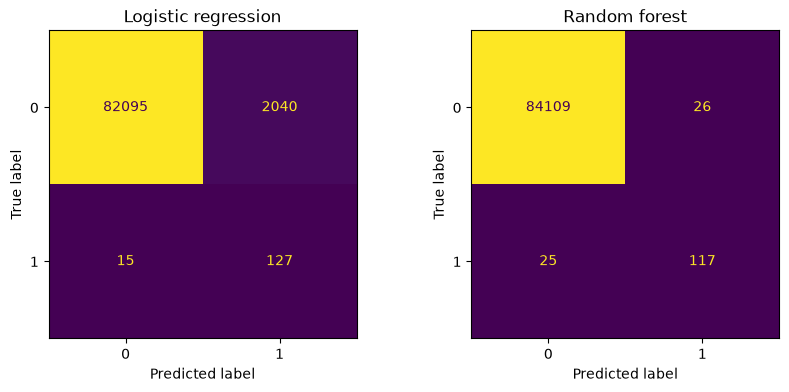

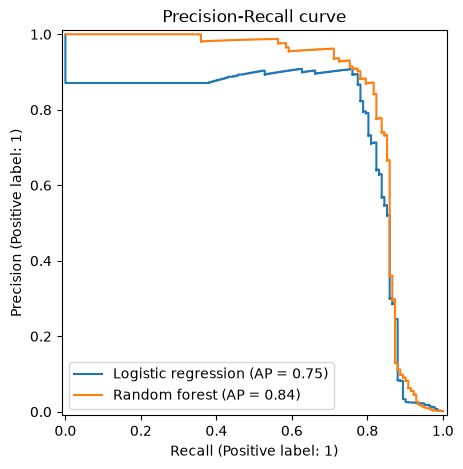

In [ ]:

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr = LogisticRegression(max_iter = 1000, class_weight='balanced', random_state=42)
lr.fit(X_train_s, y_train)
lr_pred = lr.predict(X_test_s)
lr_prob = lr.predict_proba(X_test_s)[:, 1]

rf = RandomForestClassifier(n_jobs = -1, class_weight = 'balanced', max_depth = 10, random_state = 42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

#PR AUC used for heavily imbalanced datasets (this is heavily skewed) used for fraud vs legitimate
for name, pred, prob in [('Logistic regression', lr_pred, lr_prob), ('Random forest', rf_pred, rf_prob)]:
    print(f"\n{name}")
    print(classification_report(y_test, pred, digits=3))
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))
    print("PR-AUC:", round(average_precision_score(y_test, prob), 3))


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, ax=axes[0], colorbar=False)
ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, ax=axes[1], colorbar=False)
axes[0].set_title("Logistic regression")
axes[1].set_title("Random forest")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, lr_prob, ax=ax, name="Logistic regression")
PrecisionRecallDisplay.from_predictions(y_test, rf_prob, ax=ax, name="Random forest")
plt.title("Precision-Recall curve")
plt.show()

**Models:** I chose logistic regression (a simple, interpretable linear baseline) and a random forest (an ensemble of trees that handles non-linear patterns). 
Both use `class_weight='balanced'`, which makes errors on the rare fraud class count more during training so the model does not simply ignore it.


**Results:**
Logistic regression: precision 0.059, recall 0.894, F1 0.110, PR-AUC 0.753. It catches 127 of 142 frauds but raises 2,040 false alarms.
Random forest (max depth 10): precision 0.818, recall 0.824, F1 0.821, PR-AUC 0.840. It catches 117 of 142 frauds with only 26 false alarms and 25 missed frauds.

Accuracy is high for both (about 0.976 and 0.999) but says very little here, since most transactions are legitimate. The forest is far more precise, while logistic regression catches slightly more fraud at the cost of many more false alarms.